In [1]:
import os
DATA_DIR = "/kaggle/input/datasets/nulusaikishore/plant-disease-dataset"

# Define the three dataset paths
TRAIN_DIR = "/kaggle/input/datasets/nulusaikishore/plant-disease-dataset/plant disease dataset/train"
VAL_DIR = "/kaggle/input/datasets/nulusaikishore/plant-disease-dataset/plant disease dataset/validation"
TEST_DIR = "/kaggle/input/datasets/nulusaikishore/plant-disease-dataset/plant disease dataset/test"


In [2]:
import tensorflow as tf
from tensorflow.keras.applications.densenet import preprocess_input

# Configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Load training images
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=True,
    seed=SEED
)

# Store the class names in their assigned alphabetical order
class_names = train_dataset.class_names
NUM_CLASSES = len(class_names)

# Load validation images without shuffling
val_dataset = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

# Load test images without shuffling
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

# Verify that all splits use the same class mapping
assert class_names == val_dataset.class_names
assert class_names == test_dataset.class_names

print("Number of classes:", NUM_CLASSES)
print("Class names:", class_names)

Found 27986 files belonging to 33 classes.


I0000 00:00:1791932708.092142      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791932708.096231      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 6000 files belonging to 33 classes.
Found 6014 files belonging to 33 classes.
Number of classes: 33
Class names: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Cherry___Powdery_mildew', 'Cherry___healthy', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___Northern_Leaf_Blight', 'Corn___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato

In [3]:
# Transform training images for DenseNet121
train_dataset = train_dataset.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

# Transform validation images using the same preprocessing
val_dataset = val_dataset.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

# Transform test images using the same preprocessing
test_dataset = test_dataset.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

# Prefetch batches to help overlap data loading and model execution
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
val_dataset = val_dataset.prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

In [4]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import DenseNet121

# Load DenseNet121 pretrained on ImageNet
# Remove its original 1000-class output layer
base_model = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained feature extractor
base_model.trainable = False

# Define the input for your plant images
inputs = layers.Input(shape=(224, 224, 3))

# Extract features using the frozen DenseNet121 model
x = base_model(inputs, training=False)

# Convert the feature maps into a feature vector
x = layers.GlobalAveragePooling2D()(x)

# Apply dropout to help reduce overfitting
x = layers.Dropout(0.3)(x)

# Add an output neuron for each of the 33 classes
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

# Assemble the complete model
model_densenet = models.Model(inputs, outputs)

# Display the model structure and parameter counts
model_densenet.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 33)             │        33,825 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,071,329 (26.97 MB)

 Trainable params: 33,825 (132.13 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [5]:
# Configure the optimizer, loss function, and evaluation metric
model_densenet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [6]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Count images in each training class folder
class_counts = []

for class_name in class_names:
    class_dir = os.path.join(TRAIN_DIR, class_name)

    # Count supported image files in the folder
    count = sum(
        1 for filename in os.listdir(class_dir)
        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    )

    class_counts.append(count)

# Create one label for each training image
y_train_labels = np.repeat(
    np.arange(NUM_CLASSES),
    class_counts
)

# Calculate weights inversely related to class frequency
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=y_train_labels
)

# Create the dictionary required by model.fit()
class_weights = dict(enumerate(weights))

print("Calculated class weights for", len(class_weights), "classes")

Calculated class weights for 33 classes


In [7]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Save the checkpoint with the lowest validation loss
checkpoint = ModelCheckpoint(
    filepath="/kaggle/working/best_densenet121.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Stop if validation loss fails to improve for 3 epochs
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Train for up to 5 epochs as an initial experiment
history = model_densenet.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    class_weight=class_weights,
    #callbacks=[checkpoint, early_stopping],
    verbose=1
)

Epoch 1/20
  1/875 ━━━━━━━━━━━━━━━━━━━━ 6:59:38 29s/step - accuracy: 0.0312 - loss: 3.9859

I0000 00:00:1791932752.274456      76 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


875/875 ━━━━━━━━━━━━━━━━━━━━ 142s 129ms/step - accuracy: 0.7297 - loss: 0.9882 - val_accuracy: 0.9085 - val_loss: 0.3582
Epoch 2/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 83s 94ms/step - accuracy: 0.8867 - loss: 0.3631 - val_accuracy: 0.9380 - val_loss: 0.2389
Epoch 3/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 82s 94ms/step - accuracy: 0.9041 - loss: 0.2832 - val_accuracy: 0.9408 - val_loss: 0.2050
Epoch 4/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 82s 94ms/step - accuracy: 0.9147 - loss: 0.2457 - val_accuracy: 0.9495 - val_loss: 0.1728
Epoch 5/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 82s 94ms/step - accuracy: 0.9207 - loss: 0.2239 - val_accuracy: 0.9467 - val_loss: 0.1653
Epoch 6/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 82s 93ms/step - accuracy: 0.9233 - loss: 0.2087 - val_accuracy: 0.9575 - val_loss: 0.1389
Epoch 7/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 82s 94ms/step - accuracy: 0.9234 - loss: 0.2045 - val_accuracy: 0.9535 - val_loss: 0.1508
Epoch 8/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 82s 94ms/step - accuracy: 0.9273 - loss: 0.1960 - val_accur

In [8]:
images, labels = next(iter(train_dataset))

predictions = model_densenet.predict(images[:8], verbose=0)

print("Predicted classes:",
      tf.argmax(predictions, axis=1).numpy())

print("Actual classes:",
      labels[:8].numpy())

print("Maximum probability per image:",
      tf.reduce_max(predictions, axis=1).numpy())

Predicted classes: [23 30  4 23 12  0 25 23]
Actual classes: [23 30  4 23 12  0 25 23]
Maximum probability per image: [0.55818367 0.9737337  0.99998605 0.9997415  1.         0.99536645
 0.99887186 0.8690692 ]


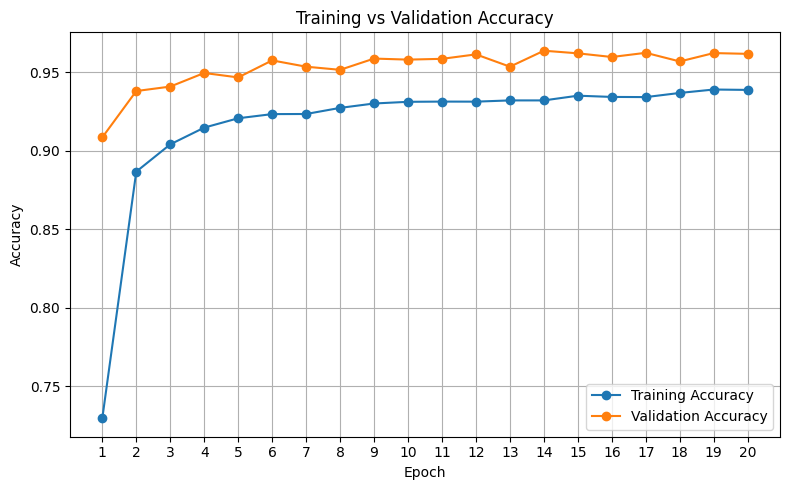

In [9]:
# Import Matplotlib for plotting graphs.
import matplotlib.pyplot as plt

# Create a list of epoch numbers starting from 1.
epochs = range(1, len(history.history["accuracy"]) + 1)

# Create a new figure for the accuracy plot.
plt.figure(figsize=(8, 5))

# Plot the training accuracy for each epoch.
plt.plot(epochs, history.history["accuracy"], marker="o", label="Training Accuracy")

# Plot the validation accuracy for each epoch.
plt.plot(epochs, history.history["val_accuracy"], marker="o", label="Validation Accuracy")

# Add a title and axis labels.
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

# Display epoch numbers as x-axis ticks.
plt.xticks(list(epochs))

# Display the legend and grid.
plt.legend()
plt.grid(True)

# Adjust spacing and display the graph.
plt.tight_layout()
plt.show()

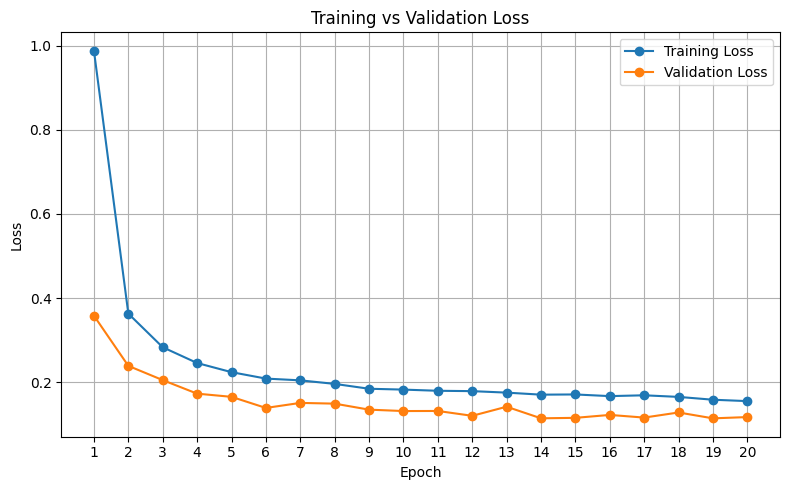

In [10]:
# Create a new figure for the loss plot.
plt.figure(figsize=(8, 5))

# Plot the training loss for each epoch.
plt.plot(epochs, history.history["loss"], marker="o", label="Training Loss")

# Plot the validation loss for each epoch.
plt.plot(epochs, history.history["val_loss"], marker="o", label="Validation Loss")

# Add a title and axis labels.
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

# Display epoch numbers as x-axis ticks.
plt.xticks(list(epochs))

# Display the legend and grid.
plt.legend()
plt.grid(True)

# Adjust spacing and display the graph.
plt.tight_layout()
plt.show()

In [11]:
test_loss, test_accuracy = model_densenet.evaluate(test_dataset)

# Print the final evaluation metrics.
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy percentage: {test_accuracy * 100:.2f}%")

188/188 ━━━━━━━━━━━━━━━━━━━━ 30s 157ms/step - accuracy: 0.9626 - loss: 0.1204
Test loss: 0.1204
Test accuracy: 0.9626
Test accuracy percentage: 96.26%


In [12]:
# Import the classification report function.
from sklearn.metrics import classification_report

# Collect the actual integer labels from the test dataset.
y_true = np.concatenate([
    labels.numpy() for _, labels in test_dataset
])

# Predict probabilities for each test image.
y_prob = model_densenet.predict(test_dataset)

# Select the class with the highest predicted probability.
y_pred = np.argmax(y_prob, axis=1)

# Print precision, recall, F1-score, and support for all classes.
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    digits=4,
    zero_division=0
))

188/188 ━━━━━━━━━━━━━━━━━━━━ 38s 141ms/step
                                               precision    recall  f1-score   support

                           Apple___Apple_scab     0.9684    0.9684    0.9684        95
                            Apple___Black_rot     0.9894    0.9894    0.9894        94
                     Apple___Cedar_apple_rust     1.0000    1.0000    1.0000        42
                              Apple___healthy     0.9880    0.9920    0.9900       249
                      Cherry___Powdery_mildew     0.9936    0.9810    0.9873       158
                             Cherry___healthy     0.9922    0.9922    0.9922       129
   Corn___Cercospora_leaf_spot Gray_leaf_spot     0.7019    0.9481    0.8066        77
                           Corn___Common_rust     0.9944    0.9944    0.9944       179
                  Corn___Northern_Leaf_Blight     0.9580    0.7703    0.8539       148
                               Corn___healthy     0.9887    1.0000    0.9943       17

188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 78ms/step


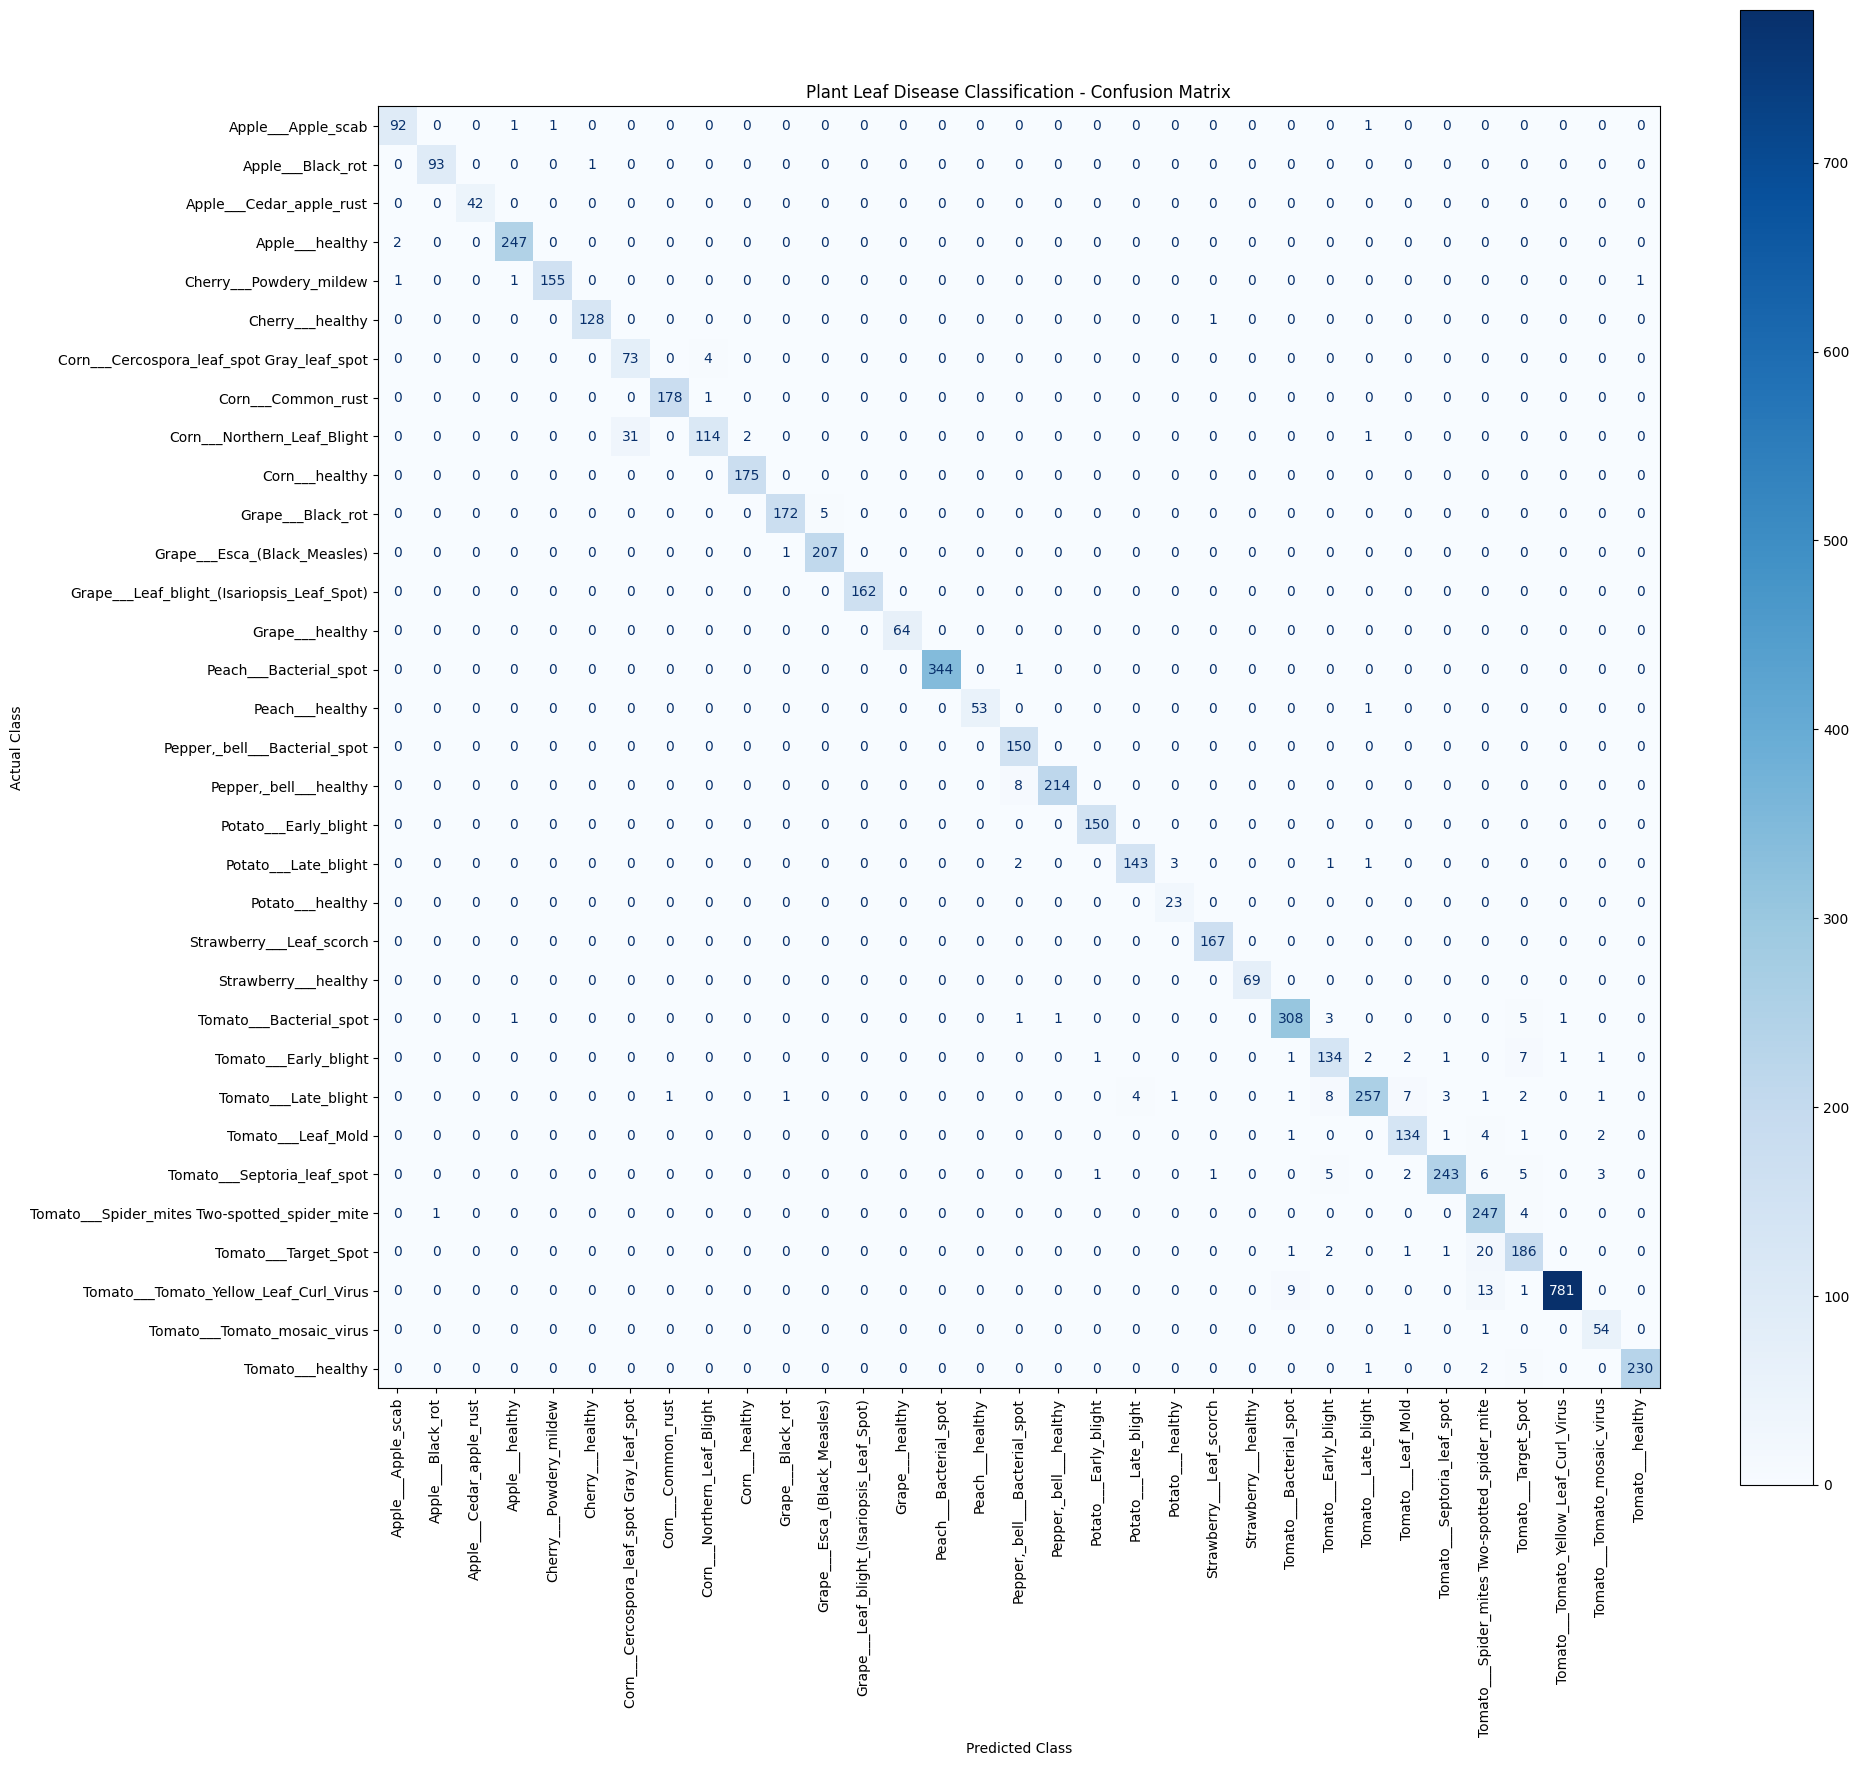

In [13]:
# Import NumPy for numerical operations.
import numpy as np

# Import Matplotlib for displaying the confusion matrix.
import matplotlib.pyplot as plt

# Import the confusion matrix calculation function.
from sklearn.metrics import confusion_matrix

# Import the ConfusionMatrixDisplay visualization utility.
from sklearn.metrics import ConfusionMatrixDisplay

# Collect the actual integer labels from all test batches.
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_dataset
])

# Predict class probabilities for every test image.
y_prob = model_densenet.predict(test_dataset)

# Select the class with the highest predicted probability.
y_pred = np.argmax(y_prob, axis=1)

# Calculate the confusion matrix using all 33 class labels.
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

# Create a large figure so the 33 class labels are more readable.
fig, ax = plt.subplots(figsize=(20, 18))

# Display the confusion matrix with class names.
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

# Draw the matrix and rotate the labels for readability.
display.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

# Add a descriptive title.
plt.title("Plant Leaf Disease Classification - Confusion Matrix")

# Label both axes.
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

# Adjust spacing to prevent label overlap.
plt.tight_layout()

# Display the confusion matrix.
plt.show()

validating densenet model

In [14]:
import os

# Save the trained DenseNet121 model to Kaggle's working directory.
MODEL_PATH = "/kaggle/working/best_densenet121.keras"

model_densenet.save(MODEL_PATH)

print("Model saved successfully!")
print("File path:", MODEL_PATH)
print("File size:", round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2), "MB")

Model saved successfully!
File path: /kaggle/working/best_densenet121.keras
File size: 28.68 MB


In [15]:
import json
from IPython.display import FileLink, display

# Save class names in the exact order used by the training dataset.
with open("/kaggle/working/class_names.json", "w") as f:
    json.dump(class_names, f, indent=4)

print("Saved", len(class_names), "class names")
display(FileLink("/kaggle/working/class_names.json"))

Saved 33 class names


/kaggle/working/class_names.json

In [16]:
import os
import json

# Make sure class_names exists in your current session.
print("Class names available:", "class_names" in globals())

if "class_names" in globals():
    path = "/kaggle/working/class_names.json"

    with open(path, "w") as f:
        json.dump(class_names, f, indent=4)

    print("File exists:", os.path.exists(path))
    print("File size:", os.path.getsize(path), "bytes")

Class names available: True
File exists: True
File size: 1027 bytes


In [17]:
import json

# Print class names in the exact order used by your model
print(json.dumps(class_names, indent=4))

[
    "Apple___Apple_scab",
    "Apple___Black_rot",
    "Apple___Cedar_apple_rust",
    "Apple___healthy",
    "Cherry___Powdery_mildew",
    "Cherry___healthy",
    "Corn___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn___Common_rust",
    "Corn___Northern_Leaf_Blight",
    "Corn___healthy",
    "Grape___Black_rot",
    "Grape___Esca_(Black_Measles)",
    "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)",
    "Grape___healthy",
    "Peach___Bacterial_spot",
    "Peach___healthy",
    "Pepper,_bell___Bacterial_spot",
    "Pepper,_bell___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy",
    "Strawberry___Leaf_scorch",
    "Strawberry___healthy",
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato___Tomato_mosaic_virus

In [18]:
import os

MODEL_PATH = "/kaggle/working/best_densenet121.keras"

print("Model exists:", os.path.exists(MODEL_PATH))

if os.path.exists(MODEL_PATH):
    print("File size:", round(os.path.getsize(MODEL_PATH) / (1024**2), 2), "MB")
else:
    print("The model file has not been saved at this path.")

Model exists: True
File size: 28.68 MB


**NASNET Implementation**

In [19]:
import tensorflow as tf
from tensorflow.keras.applications.nasnet import preprocess_input

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Load the original training images
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=True,
    seed=42
)

# Preserve the class-index mapping
class_names = train_dataset.class_names

# Load validation and test datasets without shuffling
val_dataset = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

# Confirm that all splits use the same class ordering
assert class_names == val_dataset.class_names
assert class_names == test_dataset.class_names

# Apply NASNetMobile preprocessing exactly once
train_dataset = train_dataset.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

val_dataset = val_dataset.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

# Prefetch batches to improve input pipeline throughput
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
val_dataset = val_dataset.prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)

Found 27986 files belonging to 33 classes.
Found 6000 files belonging to 33 classes.
Found 6014 files belonging to 33 classes.
Number of classes: 33


In [20]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import NASNetMobile

# Load NASNetMobile with pretrained ImageNet weights
# Exclude its original 1000-class classification head
base_model = NASNetMobile(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained feature extractor
base_model.trainable = False

# Define the model input
inputs = layers.Input(shape=(224, 224, 3))

# Extract features using the frozen NASNetMobile base
x = base_model(inputs, training=False)

# Convert feature maps into a single feature vector
x = layers.GlobalAveragePooling2D()(x)

# Add dropout to help reduce overfitting
x = layers.Dropout(0.3)(x)

# Predict probabilities for all plant disease classes
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

# Combine the layers into the final model
model_nasnet = models.Model(inputs, outputs)

# Display the architecture and parameter counts
model_nasnet.summary()

19993432/19993432 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ nasnet_mobile (Functional)      │ (None, 7, 7, 1056)     │     4,269,716 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1056)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1056)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 33)             │        34,881 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,304,597 (16.42 MB)

 Trainable params: 34,881 (136.25 KB)

 Non-trainable params: 4,269,716 (16.29 MB)

In [21]:
# Compile NASNetMobile for multiclass classification
model_nasnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [22]:
# Import the operating-system utilities for working with folders.
import os

# Import NumPy for storing the labels in an array.
import numpy as np

# Create an empty list to store the integer label of each image.
train_labels_list = []

# Loop through every class in the same order used by TensorFlow.
for class_id, class_name in enumerate(class_names):

    # Construct the path to the current class folder.
    class_dir = os.path.join(TRAIN_DIR, class_name)

    # Count image files directly inside this class folder.
    image_count = sum(
        1 for filename in os.listdir(class_dir)
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".gif"))
    )

    # Add the class label once for every image in this folder.
    train_labels_list.extend([class_id] * image_count)

# Convert the collected labels into a NumPy array.
train_labels = np.array(train_labels_list, dtype=np.int32)

# Display the number of labels collected.
print("Total training labels:", len(train_labels))

Total training labels: 27986


In [23]:
from sklearn.utils.class_weight import compute_class_weight

# Find the class IDs present in the collected labels.
unique_classes = np.unique(train_labels)

# Calculate balanced class weights using the training labels.
weights = compute_class_weight(
    class_weight="balanced",
    classes=unique_classes,
    y=train_labels
)

# Map each class ID to its calculated weight.
class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(unique_classes, weights)
}

# Display the number of class weights and their values.
print("Number of class weights:", len(class_weights))
print(class_weights)

Number of class weights: 33
{0: 1.923039923039923, 1: 1.95405669599218, 2: 4.4169823232323235, 3: 0.7380858190257668, 4: 1.152256258234519, 5: 1.4205370285772296, 6: 2.3622858107537774, 7: 1.0168592398808227, 8: 1.2308571931213441, 9: 1.0431249767043125, 10: 1.0267077555213149, 11: 0.8760956674179815, 12: 1.1262425047285605, 13: 2.865069615069615, 14: 0.5277290641323, 15: 3.3653198653198655, 16: 1.216729707404026, 17: 0.8201746673700252, 18: 1.2115151515151514, 19: 1.2115151515151514, 20: 8.000571755288737, 21: 1.0928616057482037, 22: 2.6584971976821508, 23: 0.5699332029977191, 24: 1.2115151515151514, 25: 0.6343011264477233, 26: 1.2733642733642734, 27: 0.6844718370142099, 28: 0.7229843188922472, 29: 0.8636055051533666, 30: 0.22620981756751296, 31: 3.2492743527226287, 32: 0.7619592147894034}


In [24]:
# Train the classifier using the frozen NASNetMobile feature extractor
history = model_nasnet.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    class_weight=class_weights,
    #callbacks=[checkpoint, early_stopping],
    verbose=1
)

Epoch 1/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 163s 136ms/step - accuracy: 0.6718 - loss: 1.1869 - val_accuracy: 0.8237 - val_loss: 0.6274
Epoch 2/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 55s 63ms/step - accuracy: 0.8175 - loss: 0.5841 - val_accuracy: 0.8603 - val_loss: 0.4891
Epoch 3/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 56s 64ms/step - accuracy: 0.8445 - loss: 0.4704 - val_accuracy: 0.8753 - val_loss: 0.4208
Epoch 4/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 55s 63ms/step - accuracy: 0.8559 - loss: 0.4151 - val_accuracy: 0.8855 - val_loss: 0.3843
Epoch 5/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 55s 63ms/step - accuracy: 0.8684 - loss: 0.3771 - val_accuracy: 0.8927 - val_loss: 0.3469
Epoch 6/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 55s 63ms/step - accuracy: 0.8725 - loss: 0.3530 - val_accuracy: 0.8925 - val_loss: 0.3484
Epoch 7/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 55s 63ms/step - accuracy: 0.8797 - loss: 0.3321 - val_accuracy: 0.8980 - val_loss: 0.3360
Epoch 8/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 55s 63ms/step - accuracy: 0.8808 - loss: 0.3244 

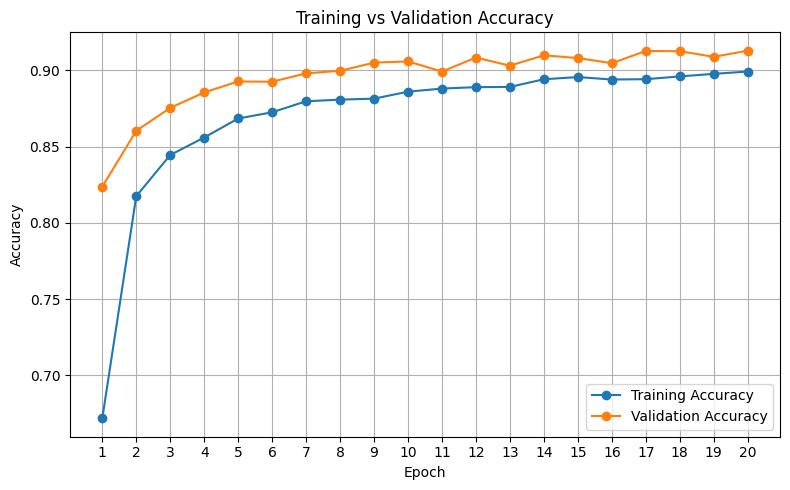

In [25]:
# Import Matplotlib for plotting graphs.
import matplotlib.pyplot as plt

# Create a list of epoch numbers starting from 1.
epochs = range(1, len(history.history["accuracy"]) + 1)

# Create a new figure for the accuracy plot.
plt.figure(figsize=(8, 5))

# Plot the training accuracy for each epoch.
plt.plot(epochs, history.history["accuracy"], marker="o", label="Training Accuracy")

# Plot the validation accuracy for each epoch.
plt.plot(epochs, history.history["val_accuracy"], marker="o", label="Validation Accuracy")

# Add a title and axis labels.
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

# Display epoch numbers as x-axis ticks.
plt.xticks(list(epochs))

# Display the legend and grid.
plt.legend()
plt.grid(True)

# Adjust spacing and display the graph.
plt.tight_layout()
plt.show()

In [26]:
test_loss, test_accuracy = model_nasnet.evaluate(test_dataset)

# Print the final evaluation metrics.
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy percentage: {test_accuracy * 100:.2f}%")

188/188 ━━━━━━━━━━━━━━━━━━━━ 30s 159ms/step - accuracy: 0.9049 - loss: 0.2842
Test loss: 0.2842
Test accuracy: 0.9049
Test accuracy percentage: 90.49%


In [27]:
# Import the classification report function.
from sklearn.metrics import classification_report

# Collect the actual integer labels from the test dataset.
y_true = np.concatenate([
    labels.numpy() for _, labels in test_dataset
])

# Predict probabilities for each test image.
y_prob = model_nasnet.predict(test_dataset)

# Select the class with the highest predicted probability.
y_pred = np.argmax(y_prob, axis=1)

# Print precision, recall, F1-score, and support for all classes.
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    digits=4,
    zero_division=0
))

188/188 ━━━━━━━━━━━━━━━━━━━━ 52s 165ms/step
                                               precision    recall  f1-score   support

                           Apple___Apple_scab     0.8866    0.9053    0.8958        95
                            Apple___Black_rot     0.9479    0.9681    0.9579        94
                     Apple___Cedar_apple_rust     0.9756    0.9524    0.9639        42
                              Apple___healthy     0.9494    0.9799    0.9644       249
                      Cherry___Powdery_mildew     0.9512    0.9873    0.9689       158
                             Cherry___healthy     1.0000    0.9767    0.9882       129
   Corn___Cercospora_leaf_spot Gray_leaf_spot     0.6667    0.8312    0.7399        77
                           Corn___Common_rust     0.9944    1.0000    0.9972       179
                  Corn___Northern_Leaf_Blight     0.8906    0.7703    0.8261       148
                               Corn___healthy     0.9943    1.0000    0.9972       17

188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 53ms/step


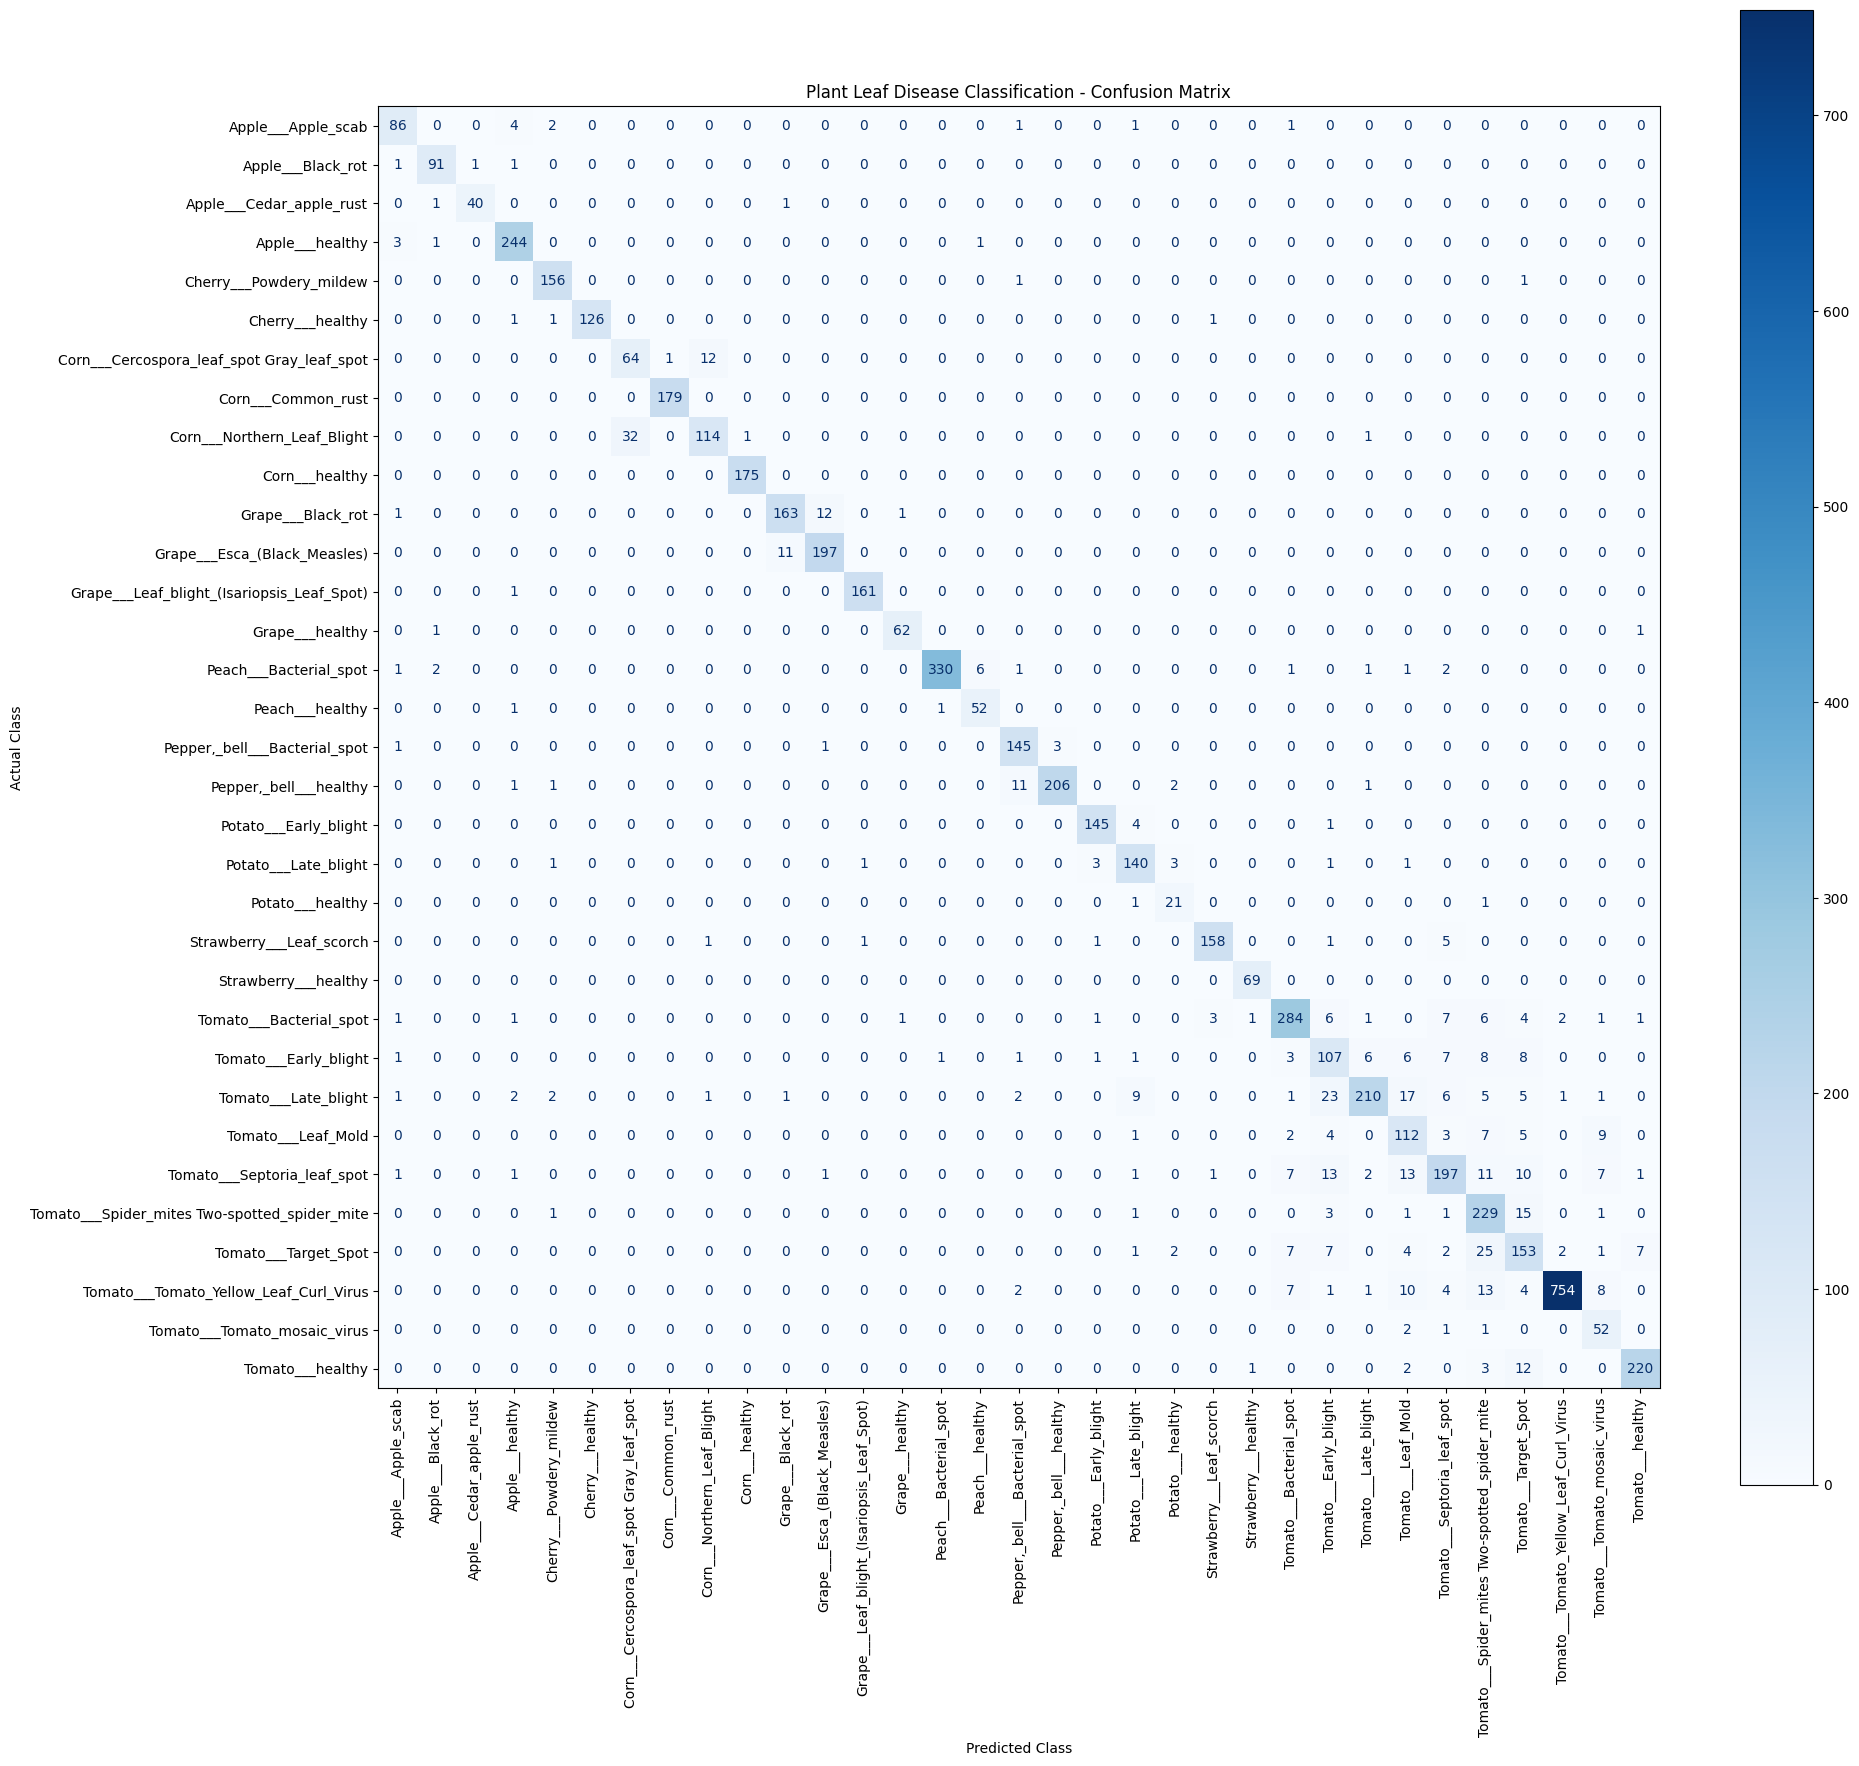

In [28]:
# Import NumPy for numerical operations.
import numpy as np

# Import Matplotlib for displaying the confusion matrix.
import matplotlib.pyplot as plt

# Import the confusion matrix calculation function.
from sklearn.metrics import confusion_matrix

# Import the ConfusionMatrixDisplay visualization utility.
from sklearn.metrics import ConfusionMatrixDisplay

# Collect the actual integer labels from all test batches.
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_dataset
])

# Predict class probabilities for every test image.
y_prob = model_nasnet.predict(test_dataset)

# Select the class with the highest predicted probability.
y_pred = np.argmax(y_prob, axis=1)

# Calculate the confusion matrix using all 33 class labels.
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

# Create a large figure so the 33 class labels are more readable.
fig, ax = plt.subplots(figsize=(20, 18))

# Display the confusion matrix with class names.
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

# Draw the matrix and rotate the labels for readability.
display.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

# Add a descriptive title.
plt.title("Plant Leaf Disease Classification - Confusion Matrix")

# Label both axes.
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

# Adjust spacing to prevent label overlap.
plt.tight_layout()

# Display the confusion matrix.
plt.show()